In [1]:
import json
import logging
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import confusion_matrix

c:\Users\use\Desktop\Credit Card Fraud Detection\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
IMBALANCE_MODELS_DIR = (
    PROJECT_ROOT / "models" / "supervised" / "class_imbalance_models"
)

SELECTED_MODEL_NAME = "Random Forest | Class weighting"
SELECTED_MODEL_PATH = (
    IMBALANCE_MODELS_DIR
    / "random_forest_class_weighting"
    / "model.joblib"
)

RANDOM_SEED = 42
SHAP_SAMPLE_SIZE = 2000
POSITIVE_CLASS_INDEX = 1

SHAP_SUMMARY_PATH = FIGURES_DIR / "shap_summary.png"
SHAP_IMPORTANCE_PATH = FIGURES_DIR / "shap_feature_importance.png"
SHAP_TRUE_POSITIVE_PATH = FIGURES_DIR / "shap_true_positive_explanation.png"
SHAP_FALSE_POSITIVE_PATH = FIGURES_DIR / "shap_false_positive_explanation.png"
SHAP_FALSE_NEGATIVE_PATH = FIGURES_DIR / "shap_false_negative_explanation.png"
SHAP_REPORT_PATH = REPORTS_DIR / "shap_explainability_report.md"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Selected model: %s", SELECTED_MODEL_NAME)
logger.info("SHAP sample size: %s", SHAP_SAMPLE_SIZE)

2026-11-01 12:25:50,653 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 12:25:50,655 | INFO | Selected model: Random Forest | Class weighting
2026-11-01 12:25:50,657 | INFO | SHAP sample size: 2000


In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

X_validation_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_validation)
)

if "Class" in X_validation_engineered.columns:
    raise ValueError("Target leakage detected in validation features.")

logger.info("Validation features: %s", X_validation_engineered.shape)
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 12:25:50,877 | INFO | Validation features: (42559, 32)
2026-11-01 12:25:50,880 | INFO | Validation fraud count: 71


In [4]:
if not SELECTED_MODEL_PATH.exists():
    raise FileNotFoundError(f"Selected model not found: {SELECTED_MODEL_PATH}")

selected_pipeline = joblib.load(SELECTED_MODEL_PATH)

if not hasattr(selected_pipeline, "named_steps"):
    raise ValueError("The selected artifact is not a scikit-learn pipeline.")

if "random_forest" not in selected_pipeline.named_steps:
    raise ValueError(
        "The selected pipeline does not contain a 'random_forest' step."
    )

random_forest_model = selected_pipeline.named_steps["random_forest"]

if not hasattr(random_forest_model, "predict_proba"):
    raise ValueError("The selected model does not support probability predictions.")

shap_explainer = shap.TreeExplainer(random_forest_model)

logger.info("Selected model loaded successfully.")
logger.info("SHAP TreeExplainer created successfully.")

2026-11-01 12:25:51,117 | INFO | Selected model loaded successfully.
2026-11-01 12:25:51,120 | INFO | SHAP TreeExplainer created successfully.


In [5]:
if SHAP_SAMPLE_SIZE < 3:
    raise ValueError("SHAP sample size must be at least 3.")

validation_scores_array = selected_pipeline.predict_proba(
    X_validation_engineered
)[:, 1]

validation_predictions_array = (
    validation_scores_array >= 0.5
).astype(int)

validation_scores = pd.Series(
    validation_scores_array,
    index=X_validation_engineered.index,
    name="fraud_score",
)

validation_predictions = pd.Series(
    validation_predictions_array,
    index=X_validation_engineered.index,
    name="fraud_prediction",
)

true_positive_mask = (y_validation == 1) & (validation_predictions == 1)
false_positive_mask = (y_validation == 0) & (validation_predictions == 1)
false_negative_mask = (y_validation == 1) & (validation_predictions == 0)

if not true_positive_mask.any():
    raise ValueError("No true positives found in the validation set.")

if not false_positive_mask.any():
    raise ValueError("No false positives found in the validation set.")

if not false_negative_mask.any():
    raise ValueError("No false negatives found in the validation set.")

true_positive_index = validation_scores[true_positive_mask].idxmax()
false_positive_index = validation_scores[false_positive_mask].idxmax()
false_negative_index = validation_scores[false_negative_mask].idxmax()

required_explanation_indices = [
    true_positive_index,
    false_positive_index,
    false_negative_index,
]

remaining_sample_size = SHAP_SAMPLE_SIZE - len(required_explanation_indices)

random_sample_indices = X_validation_engineered.drop(
    index=required_explanation_indices
).sample(
    n=remaining_sample_size,
    random_state=RANDOM_SEED,
).index

shap_sample_indices = required_explanation_indices + list(random_sample_indices)

X_shap_sample = X_validation_engineered.loc[shap_sample_indices]
y_shap_sample = y_validation.loc[shap_sample_indices]
shap_sample_scores = validation_scores.loc[shap_sample_indices]
shap_sample_predictions = validation_predictions.loc[shap_sample_indices]

logger.info("SHAP sample shape: %s", X_shap_sample.shape)
logger.info(
    "SHAP sample fraud count: %s",
    int(y_shap_sample.sum()),
)
logger.info(
    "Required explanation indices: %s",
    {
        "true_positive": true_positive_index,
        "false_positive": false_positive_index,
        "false_negative": false_negative_index,
    },
)

2026-11-01 12:25:51,602 | INFO | SHAP sample shape: (2000, 32)
2026-11-01 12:25:51,603 | INFO | SHAP sample fraud count: 7
2026-11-01 12:25:51,605 | INFO | Required explanation indices: {'true_positive': np.int64(42936), 'false_positive': np.int64(43281), 'false_negative': np.int64(6971)}


In [6]:
shap_values = shap_explainer.shap_values(X_shap_sample)

if isinstance(shap_values, list):
    shap_values_positive_class = shap_values[POSITIVE_CLASS_INDEX]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values_positive_class = shap_values[:, :, POSITIVE_CLASS_INDEX]
else:
    raise ValueError(
        "Unexpected SHAP output format. Expected a list or three-dimensional array."
    )

if shap_values_positive_class.shape != X_shap_sample.shape:
    raise ValueError(
        "SHAP values and SHAP sample shapes do not match."
    )

logger.info(
    "SHAP values calculated: %s",
    shap_values_positive_class.shape,
)

2026-11-01 12:27:06,858 | INFO | SHAP values calculated: (2000, 32)


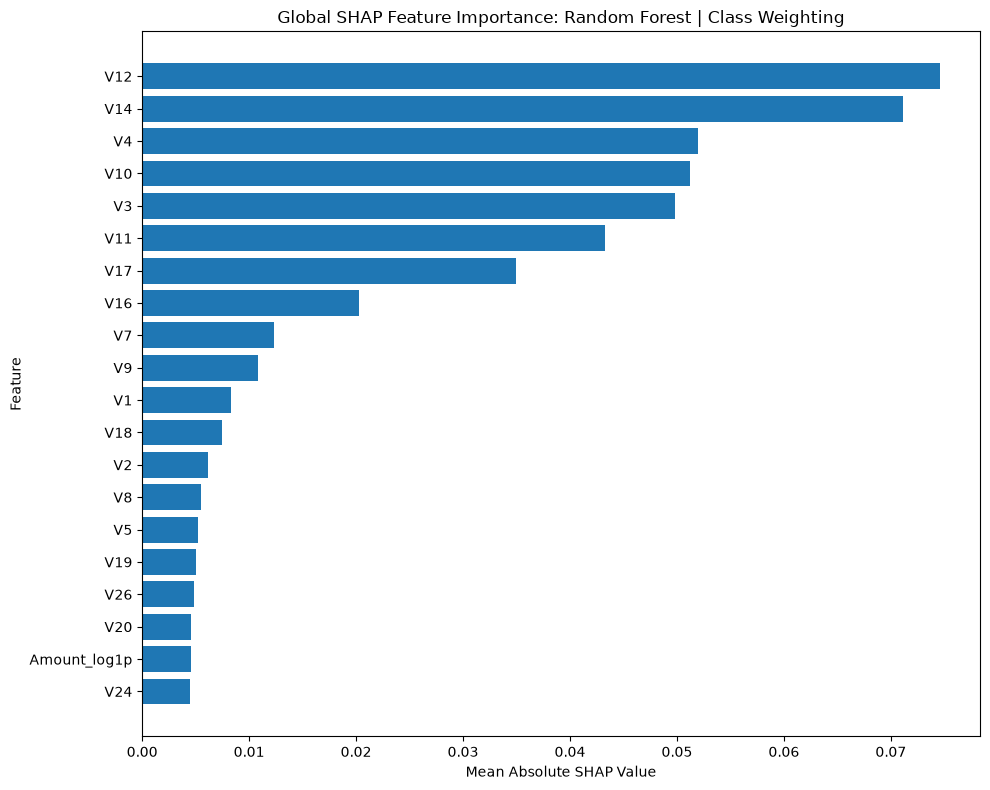

2026-11-01 12:27:09,527 | INFO | Global SHAP feature-importance figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\shap_feature_importance.png


,feature,mean_absolute_shap_value
12,V12,0.074604
14,V14,0.071109
4,V4,0.051970
10,V10,0.051205
3,V3,0.049813
11,V11,0.043228
17,V17,0.034913
16,V16,0.020308
7,V7,0.012303
9,V9,0.010852


In [7]:
mean_absolute_shap_values = np.abs(
    shap_values_positive_class
).mean(axis=0)

shap_importance_dataframe = pd.DataFrame(
    {
        "feature": X_shap_sample.columns,
        "mean_absolute_shap_value": mean_absolute_shap_values,
    }
).sort_values(
    by="mean_absolute_shap_value",
    ascending=False,
)

plt.figure(figsize=(10, 8))
plt.barh(
    shap_importance_dataframe["feature"].head(20)[::-1],
    shap_importance_dataframe["mean_absolute_shap_value"].head(20)[::-1],
)
plt.title("Global SHAP Feature Importance: Random Forest | Class Weighting")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(SHAP_IMPORTANCE_PATH, dpi=300, bbox_inches="tight")
plt.show()

logger.info(
    "Global SHAP feature-importance figure saved to: %s",
    SHAP_IMPORTANCE_PATH,
)

shap_importance_dataframe.head(20)

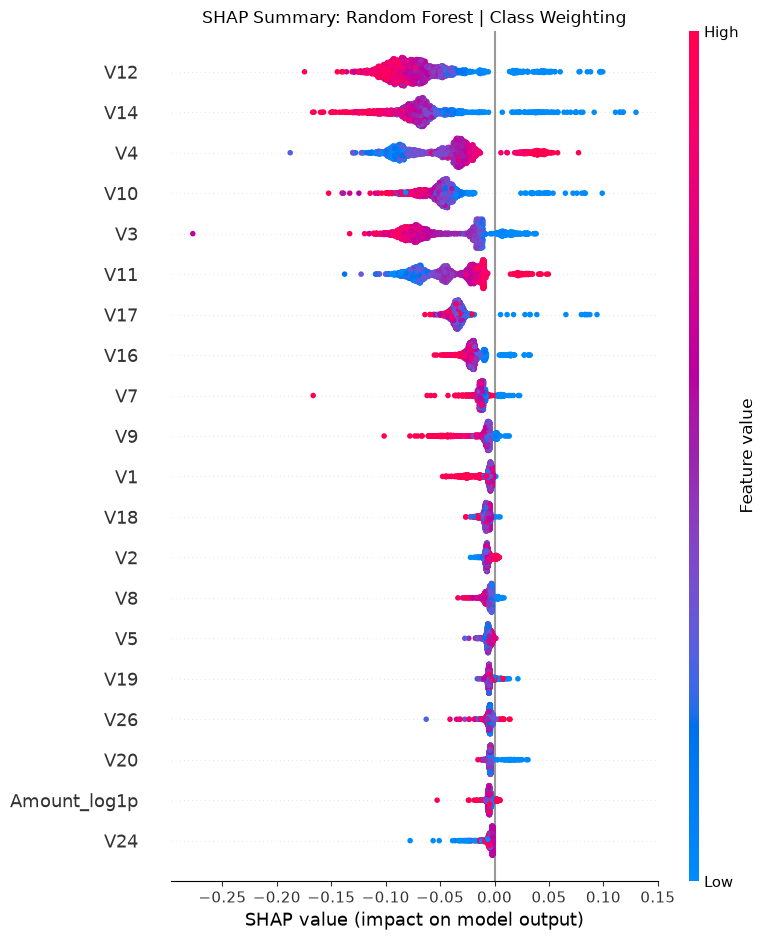

2026-11-01 12:27:16,139 | INFO | SHAP summary figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\shap_summary.png


In [8]:
plt.figure()
shap.summary_plot(
    shap_values_positive_class,
    X_shap_sample,
    show=False,
)
plt.title("SHAP Summary: Random Forest | Class Weighting")
plt.tight_layout()
plt.savefig(SHAP_SUMMARY_PATH, dpi=300, bbox_inches="tight")
plt.show()

logger.info(
    "SHAP summary figure saved to: %s",
    SHAP_SUMMARY_PATH,
)

In [9]:
def select_individual_explanations(
    y_true: pd.Series,
    predictions: pd.Series,
    scores: pd.Series,
) -> dict[str, int]:
    """Select one high-confidence true positive, false positive, and false negative."""
    true_positive_mask = (y_true == 1) & (predictions == 1)
    false_positive_mask = (y_true == 0) & (predictions == 1)
    false_negative_mask = (y_true == 1) & (predictions == 0)

    if not true_positive_mask.any():
        raise ValueError("No true positives found in the SHAP sample.")

    if not false_positive_mask.any():
        raise ValueError("No false positives found in the SHAP sample.")

    if not false_negative_mask.any():
        raise ValueError("No false negatives found in the SHAP sample.")

    true_positive_index = scores[true_positive_mask].idxmax()
    false_positive_index = scores[false_positive_mask].idxmax()
    false_negative_index = scores[false_negative_mask].idxmax()

    return {
        "true_positive": true_positive_index,
        "false_positive": false_positive_index,
        "false_negative": false_negative_index,
    }


individual_explanation_indices = select_individual_explanations(
    y_true=y_shap_sample,
    predictions=shap_sample_predictions,
    scores=shap_sample_scores,
)

logger.info(
    "Selected individual explanation indices: %s",
    individual_explanation_indices,
)

2026-11-01 12:27:16,201 | INFO | Selected individual explanation indices: {'true_positive': np.int64(42936), 'false_positive': np.int64(43281), 'false_negative': np.int64(6971)}


2026-11-01 12:27:16,248 | INFO | Generating true_positive explanation for validation index: 42936


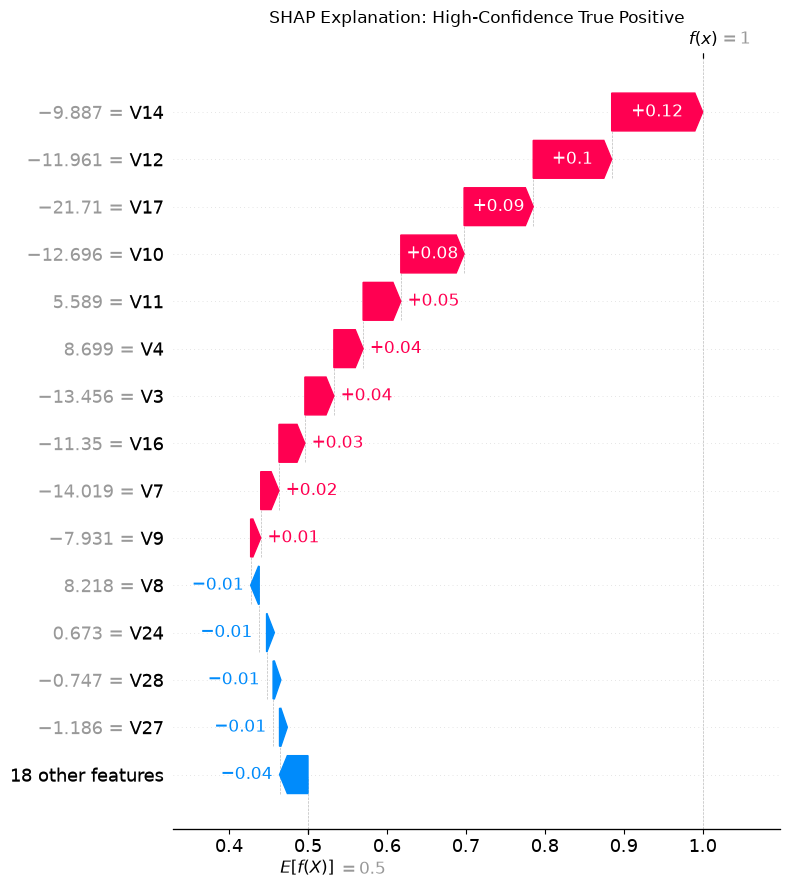

2026-11-01 12:27:19,984 | INFO | Generating false_positive explanation for validation index: 43281


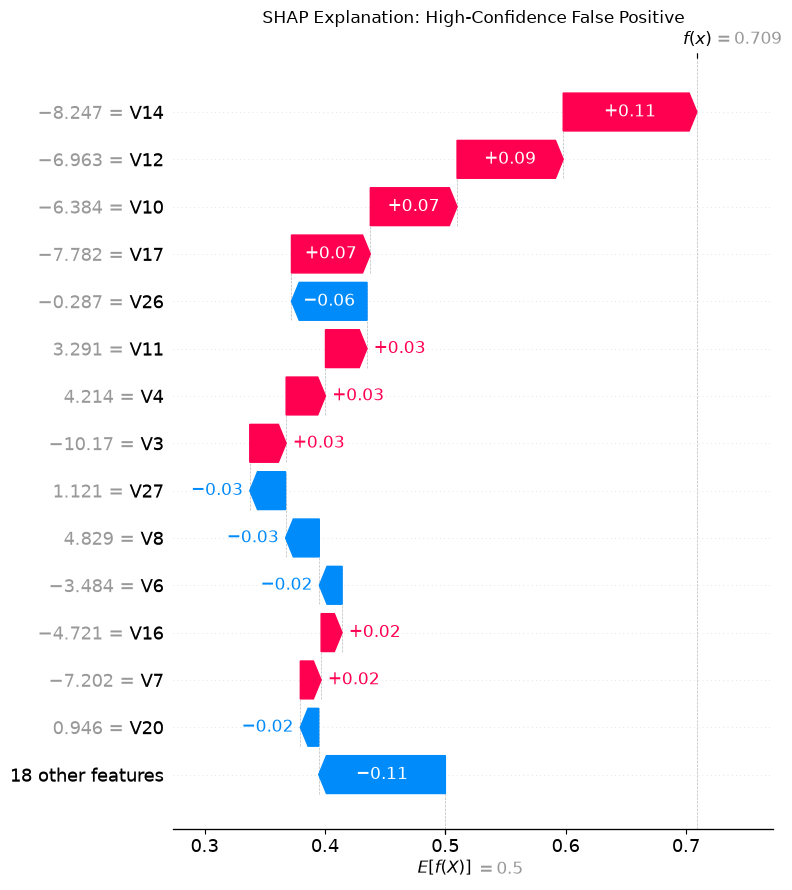

2026-11-01 12:27:22,694 | INFO | Generating false_negative explanation for validation index: 6971


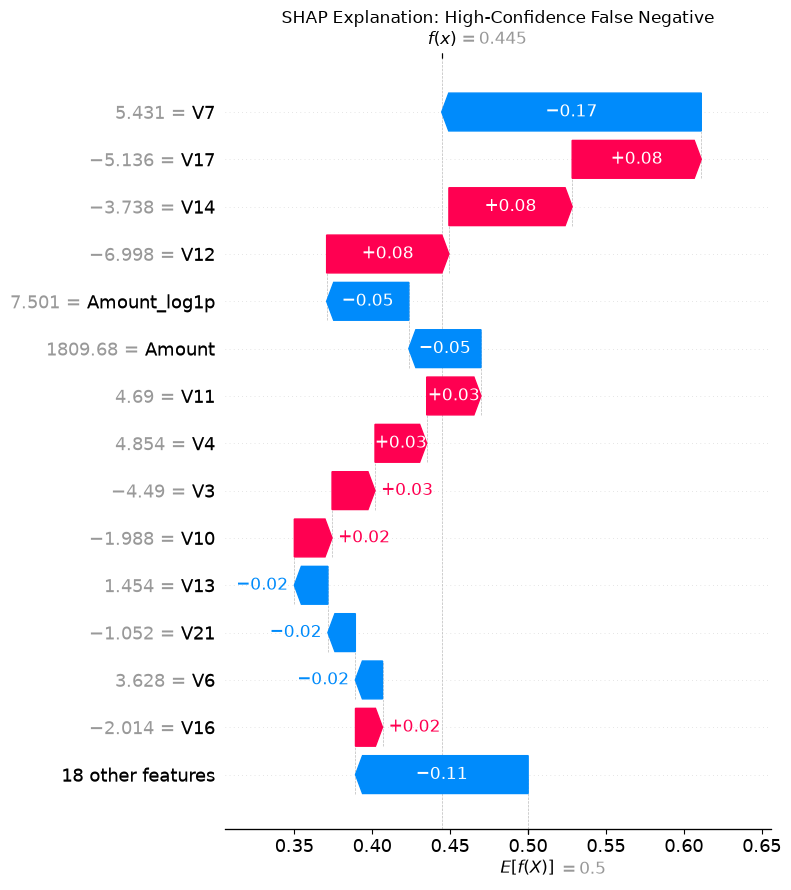

2026-11-01 12:27:26,159 | INFO | Individual SHAP explanations generated.


In [10]:
def get_positive_class_base_value(explainer) -> float:
    """Return the SHAP base value for the positive fraud class."""
    expected_value = explainer.expected_value

    if isinstance(expected_value, (list, tuple, np.ndarray)):
        if len(expected_value) <= POSITIVE_CLASS_INDEX:
            raise ValueError(
                "SHAP explainer does not contain a positive-class base value."
            )

        return float(expected_value[POSITIVE_CLASS_INDEX])

    return float(expected_value)


def plot_individual_shap_explanation(
    explanation_index,
    shap_values_positive_class: np.ndarray,
    X_shap_sample: pd.DataFrame,
    positive_class_base_value: float,
    title: str,
    output_path: Path,
) -> None:
    """Generate and save a SHAP waterfall explanation for one transaction."""
    sample_position = X_shap_sample.index.get_loc(explanation_index)

    explanation = shap.Explanation(
        values=shap_values_positive_class[sample_position],
        base_values=positive_class_base_value,
        data=X_shap_sample.loc[explanation_index],
        feature_names=list(X_shap_sample.columns),
    )

    plt.figure()
    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False,
    )
    plt.title(title)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


positive_class_base_value = get_positive_class_base_value(shap_explainer)

explanation_titles = {
    "true_positive": "SHAP Explanation: High-Confidence True Positive",
    "false_positive": "SHAP Explanation: High-Confidence False Positive",
    "false_negative": "SHAP Explanation: High-Confidence False Negative",
}

explanation_paths = {
    "true_positive": SHAP_TRUE_POSITIVE_PATH,
    "false_positive": SHAP_FALSE_POSITIVE_PATH,
    "false_negative": SHAP_FALSE_NEGATIVE_PATH,
}

for explanation_type, explanation_index in individual_explanation_indices.items():
    logger.info(
        "Generating %s explanation for validation index: %s",
        explanation_type,
        explanation_index,
    )

    plot_individual_shap_explanation(
        explanation_index=explanation_index,
        shap_values_positive_class=shap_values_positive_class,
        X_shap_sample=X_shap_sample,
        positive_class_base_value=positive_class_base_value,
        title=explanation_titles[explanation_type],
        output_path=explanation_paths[explanation_type],
    )

logger.info("Individual SHAP explanations generated.")

In [11]:
def write_shap_report(
    importance_dataframe: pd.DataFrame,
    explanation_indices: dict[str, int],
    report_path: Path,
) -> None:
    """Write a concise SHAP explainability report."""
    report_lines = [
        "# SHAP Explainability Report",
        "",
        "## Scope",
        "",
        f"- Selected model: `{SELECTED_MODEL_NAME}`",
        f"- Feature configuration: `log_amount_and_time_hours`",
        f"- SHAP sample size: {SHAP_SAMPLE_SIZE:,}",
        "- Data source: Validation set",
        "- Positive class: Fraudulent transaction (`Class = 1`)",
        "- Test set: Not used",
        "",
        "## Important Limitation",
        "",
        "- The features `V1` through `V28` are anonymized transformed variables.",
        "- Their original business meanings are unavailable.",
        "- SHAP explains how the model uses these features; it does not identify the cause of fraud.",
        "- SHAP values do not prove that a transaction is fraudulent.",
        "",
        "## Global Feature Importance",
        "",
    ]

    for _, row in importance_dataframe.head(15).iterrows():
        report_lines.append(
            f"- `{row['feature']}`: {row['mean_absolute_shap_value']:.6f}"
        )

    report_lines.extend(
        [
            "",
            "## Individual Explanations",
            "",
            f"- High-confidence true positive validation index: "
            f"`{explanation_indices['true_positive']}`",
            f"- High-confidence false positive validation index: "
            f"`{explanation_indices['false_positive']}`",
            f"- High-confidence false negative validation index: "
            f"`{explanation_indices['false_negative']}`",
            "",
            "## Interpretation",
            "",
            "- Positive SHAP values increase the model’s fraud score.",
            "- Negative SHAP values decrease the model’s fraud score.",
            "- The waterfall plots show the feature contributions for one selected transaction.",
            "- Threshold optimization and final test evaluation occur in later phases.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")


write_shap_report(
    importance_dataframe=shap_importance_dataframe,
    explanation_indices=individual_explanation_indices,
    report_path=SHAP_REPORT_PATH,
)

logger.info(
    "SHAP explainability report saved to: %s",
    SHAP_REPORT_PATH,
)

2026-11-01 12:27:26,212 | INFO | SHAP explainability report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\shap_explainability_report.md


In [12]:
required_shap_artifacts = [
    SHAP_IMPORTANCE_PATH,
    SHAP_SUMMARY_PATH,
    SHAP_TRUE_POSITIVE_PATH,
    SHAP_FALSE_POSITIVE_PATH,
    SHAP_FALSE_NEGATIVE_PATH,
    SHAP_REPORT_PATH,
]

missing_artifacts = [
    path for path in required_shap_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing SHAP artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required SHAP artifacts were generated successfully.")
print("Phase 7 SHAP explainability completed successfully.")

2026-11-01 12:27:26,245 | INFO | All required SHAP artifacts were generated successfully.


Phase 7 SHAP explainability completed successfully.
